<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">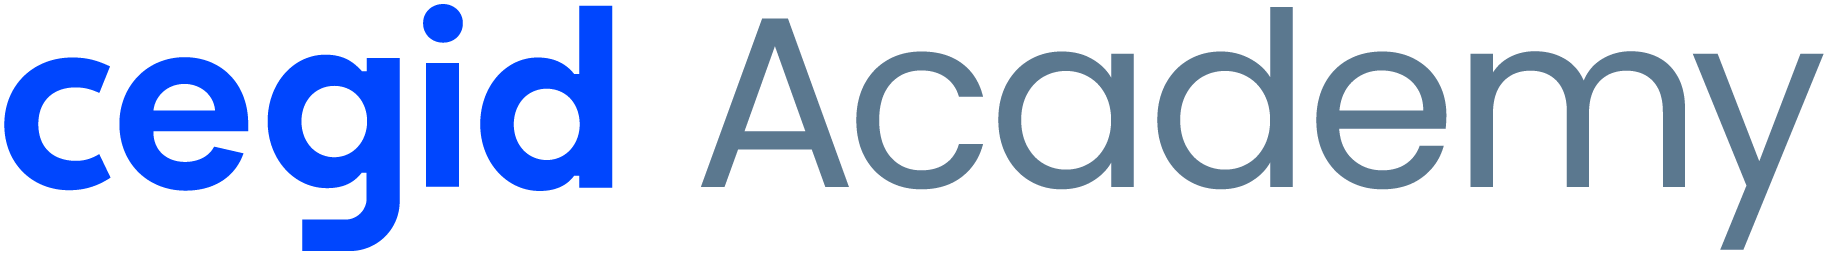<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 4 &middot; Modelação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Modeling</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M4 · M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | HR-Job-Change|
| **Grupo** |Grupo 3|
| **Formandos** |Cláudia Candeias - João Abreu |
| **Data** |18/10/2026 |
| **Dataset** |Dados_RH_Mudanca_Emprego.csv |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Treinar, afinar e comparar modelos de forma <b>justa</b> — mesma divisão treino/teste, mesmo pré-processamento, mesmas métricas — para responder à pergunta central da modelação:<br><br><b>Qual o modelo que generaliza melhor para dados novos?</b></div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Comparem <b>vários modelos</b> (pelo menos 3 + baseline). Centrar toda a modelação num único algoritmo não permite justificar a escolha final. Mantenham apenas as secções <b>[Classificação]</b>, <b>[Regressão]</b> ou <b>[Clustering]</b> que se aplicam ao vosso problema.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">O teste não serve para escolher</div>A escolha de modelos, hiperparâmetros, variáveis e limiares faz-se com a <b>validação cruzada no treino</b>. As métricas no teste que aparecem nas secções 2 e 3 servem apenas de diagnóstico: se escolherem o modelo (ou voltarem a afinar) porque teve melhor resultado no teste, o teste passa a funcionar como conjunto de validação e o resultado final fica <b>otimista</b> — deixa de ser uma estimativa honesta do desempenho em dados novos.<ul style="margin:4px 0 2px 0;"><li>decidir sempre pela média da CV (secção 6);</li><li>o <code>GridSearchCV</code> / <code>RandomizedSearchCV</code> recebe apenas <code>X_train</code> e <code>y_train</code>;</li><li>o pré-processamento fica <b>dentro</b> do Pipeline, para ser reajustado em cada fold;</li><li>se, depois de verem o teste, voltarem às Fases 3/4 para mudar alguma coisa, registem-no na Fase 5 como limitação.</li></ul></div>

**Índice**

0. Configuração · 1. Estratégia · 2. Classificação · 3. Regressão · 4. Clustering · 5. Tuning de hiperparâmetros · 6. Comparação final e seleção · 7. Avaliação detalhada no teste · 8. Guardar modelo e resultados · 9. Síntese

### 0. Configuração
<hr>

**0.1 Bibliotecas**
- Base (`numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`, `joblib`).
- scikit-learn: `train_test_split`, `cross_val_score`, `StratifiedKFold`/`KFold`, `GridSearchCV`, `RandomizedSearchCV`, `Pipeline`, `ColumnTransformer`, imputers, encoders, scalers, os modelos a usar e as métricas.

In [1]:
import json
import time
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, PrecisionRecallDisplay

from preparacao import criar_prep  # o mesmo preprocessador da Fase 3

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Carregar a configuração**
- Ler `Data/output/config_projeto.json` e criar as variáveis `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `NUM_COLS`, `CAT_COLS`, `FEATURES = NUM_COLS + CAT_COLS`, `RANDOM_STATE`.

In [2]:
with open("Data/output/config_projeto.json", encoding="utf-8") as f:
    config = json.load(f)

PROJETO = config["PROJETO"]
TARGET = config["TARGET"]
PROBLEM_TYPE = config["PROBLEM_TYPE"]
RANDOM_STATE = config["RANDOM_STATE"]
NUM_COLS = config["NUM_COLS"]
BIN_COLS = config["BIN_COLS"]
CAT_COLS = config["CAT_COLS"]

# as binárias também entram no modelo (no 03 ficaram numa lista à parte)
FEATURES = NUM_COLS + BIN_COLS + CAT_COLS
print(PROJETO, "|", PROBLEM_TYPE, "|", TARGET)
print(len(FEATURES), "features:", FEATURES)

HR-Job-Change | classificacao | procura_mudanca_emprego
14 features: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'n_nulos', 'horas_formacao_log', 'empresa_em_falta', 'nunca_mudou_emprego', 'nivel_educacao', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'area_formacao', 'dimensao_empresa', 'tipo_empresa']


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
for pasta in ["Data/input", "Data/output", "Data/analytics", "Data/models"]:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / (nome + ".png")
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print("Figura guardada em:", caminho)

**0.4 Carregar os dados da Fase 3**
- Classificação/regressão: ler `<PROJETO>_train.csv` e `<PROJETO>_test.csv` → `X_train`, `y_train`, `X_test`, `y_test`.
- Clustering: ler `<PROJETO>_dataset_clustering.csv` → `X`.

In [4]:
train = pd.read_csv(f"Data/output/{PROJETO}_train.csv", index_col="id_candidato")
test = pd.read_csv(f"Data/output/{PROJETO}_test.csv", index_col="id_candidato")

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(X_train.shape, X_test.shape)
print("% Sim no treino:", round(y_train.mean() * 100, 2), "| no teste:", round(y_test.mean() * 100, 2))

(15326, 14) (3832, 14)
% Sim no treino: 24.94 | no teste: 24.92


**0.5 Pipeline de preparação + modelo (M4)**
- Criar uma função que devolva o `ColumnTransformer` da Fase 3 (com ou sem scaling) e outra que devolva `Pipeline([("prep", prep), ("clf", modelo)])` (`"reg"` em regressão).

In [5]:
def criar_pipeline(modelo, scaling=True):
    return Pipeline([("prep", criar_prep(config, scaling)), ("clf", modelo)])  # as árvores não precisam de scaling

# tem de dar as mesmas 40 colunas da Fase 3
print(criar_prep(config).fit_transform(X_train).shape)

(15326, 40)


### 1. Definição da estratégia de modelação
<hr>

**Descrever a abordagem adotada:**

- Que tipo de problema está a ser tratado (classificação / regressão / clustering) e qual a variável-alvo?
- Qual o racional para a escolha dos modelos? O problema parece **linear ou não linear** (Fase 2)?
- Que métrica principal vai orientar a escolha (definida na Fase 1)?
- Qual é o **baseline** (modelo de referência) que os modelos têm de superar?

| Modelo | Tipo | Quando funciona melhor | Precisa de scaling? | Hiperparâmetros principais |
|---|---|---|---|---|
| Linear Regression | Regressão | relações aproximadamente lineares, pouca multicolinearidade | recomendável | `fit_intercept` |
| Logistic Regression | Classificação | separação aproximadamente linear; interpretável | sim | `C`, `max_iter` |
| Decision Tree | Ambos | relações não lineares, interações, dados mistos | não | `max_depth`, `min_samples_split`, `min_samples_leaf` |
| Random Forest | Ambos | dados complexos e com ruído; reduz a variância de uma árvore | não | `n_estimators`, `max_depth`, `max_features` |
| KNN | Classificação | fronteiras locais; poucos dados e poucas variáveis | **sim** | `n_neighbors`, `weights`, `metric` |
| K-Means | Clustering | grupos compactos; usa distâncias | **sim** | `n_clusters`, `n_init` |
| *Ridge / Lasso · Gradient Boosting* | *Regressão* | *complemento — regularização / boosting* | *sim / não* | *`alpha` · `learning_rate`, `n_estimators`* |

***Objetivo:*** justificar a estratégia antes de implementar modelos.

**Resposta:**

- **Tipo de problema:** classificação binária supervisionada. A variável-alvo é `procura_mudanca_emprego` (1 = Sim, procura mudar; 0 = Não), com cerca de 25% de "Sim" (classes desequilibradas, ~3:1).
- **Linear ou não linear?** Na Fase 2 as relações com o alvo não eram lineares: a taxa de "Sim" sobe até à Licenciatura e desce no Mestrado/Doutoramento, a experiência desce mas não em linha reta, e o sinal mais forte vem das categorias "Em falta" e do índice da cidade, que tem um comportamento quase "em degrau". Por isso esperamos que os modelos de árvores (Decision Tree, Random Forest) se saiam melhor do que a regressão logística, mas testamos as duas famílias.
- **Modelos a comparar:** Logistic Regression (simples e interpretável), Decision Tree, Random Forest e KNN, todos dentro do mesmo Pipeline da Fase 3 (com `RobustScaler` na logística e no KNN; sem scaling nas árvores). Usamos `class_weight="balanced"` sempre que o modelo permite, por causa do desequilíbrio.
- **Métrica principal para escolher:** F1 da classe "Sim" na validação cruzada. Na Fase 1 a métrica de negócio é o recall (não perder candidatos recetivos), mas escolher só pelo recall favorecia um modelo que prevê "Sim" a toda a gente; o F1 obriga a manter a precision razoável. O recall é acompanhado ao lado e ajustado depois com o limiar de decisão (Fase 5).
- **Baseline:** `DummyClassifier(strategy="most_frequent")`, que prevê sempre "Não": accuracy ≈ 75%, mas recall e F1 = 0. Qualquer modelo útil tem de o superar claramente no F1/recall, não na accuracy.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Modelos treinados no M4: classificação — Logistic Regression, Decision Tree, Random Forest, KNN; regressão — Linear Regression, Decision Tree, Random Forest; clustering — K-Means. <b>Baseline</b>: um modelo que prevê sempre a classe maioritária (ou a média) — se 90% dos casos são da mesma classe, já tem 90% de accuracy (M2.03). Os modelos só valem a pena se o superarem claramente.</div>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">CLASSIFICAÇÃO</div>

### 2. [Classificação] Treino e comparação de modelos
<hr>

Modelos (M4): **Baseline** (classe maioritária) · Logistic Regression · Decision Tree · Random Forest · KNN.

Métricas (M5): Accuracy (treino e teste), Precision, Recall, F1, ROC-AUC. Treino muito acima da validação cruzada ou do teste (> 0,10) → **overfitting**.

**2.1 [Classificação] Definições**
- Métrica principal (ex.: `"f1"`; nas aulas `"accuracy"`; em multiclasse usar `"f1_macro"` ou `"f1_weighted"` e `"roc_auc_ovr"`), `StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`.
- (Sugestão) uma função que calcule accuracy, precision, recall, F1 e ROC-AUC para um modelo e um conjunto de dados.

In [6]:
METRICA = "f1"  # F1 da classe Sim: não deixa o recall subir só por prever Sim a toda a gente
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def avaliar(modelo, X, y):
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "roc_auc": roc_auc_score(y, y_prob),
    }

**2.2 [Classificação] Treinar e avaliar os modelos (M4, M5)**
- Modelos: baseline (`DummyClassifier(strategy="most_frequent")`), Logistic Regression, Decision Tree, Random Forest e KNN — todos em Pipeline.
- Tabela com accuracy de treino e teste, precision, recall, F1, ROC-AUC e diagnóstico (treino − teste > 0,10 → overfitting).

In [7]:
# class_weight="balanced" porque só 25% são Sim (o KNN não tem esta opção)
modelos = {
    "Baseline": criar_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": criar_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree": criar_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), scaling=False),
    "Random Forest": criar_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), scaling=False),
    "KNN": criar_pipeline(KNeighborsClassifier(n_neighbors=15)),
}

linhas = []
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    tr = avaliar(modelo, X_train, y_train)
    te = avaliar(modelo, X_test, y_test)
    linhas.append([nome, tr["accuracy"], te["accuracy"], te["precision"], te["recall"], tr["f1"], te["f1"], te["roc_auc"]])

resultados = pd.DataFrame(linhas, columns=["modelo", "accuracy_treino", "accuracy_teste", "precision", "recall",
                                           "f1_treino", "f1_teste", "roc_auc"]).set_index("modelo")
# usamos o F1 para o diagnóstico porque a accuracy engana com classes desequilibradas
resultados["diagnostico"] = np.where(resultados["f1_treino"] - resultados["f1_teste"] > 0.10, "overfitting", "ok")
resultados.round(3)

,accuracy_treino,accuracy_teste,precision,recall,f1_treino,f1_teste,roc_auc,diagnostico
modelo,,,,,,,,
Baseline,0.751,0.751,0.000,0.000,0.000,0.000,0.500,ok
Logistic Regression,0.736,0.725,0.467,0.732,0.590,0.570,0.769,ok
Decision Tree,0.998,0.716,0.432,0.449,0.996,0.440,0.627,overfitting
Random Forest,0.994,0.766,0.526,0.612,0.989,0.566,0.776,overfitting
KNN,0.801,0.759,0.522,0.384,0.544,0.443,0.756,overfitting


##### Análise e Interpretação

> *Que modelo tem melhor desempenho no teste? Algum supera claramente o baseline? Há sinais de overfitting?*

**Resposta:**

- **Melhor no teste (F1):** a Logistic Regression (0,570) e a Random Forest (0,566) ficam praticamente empatadas. A logística tem o recall mais alto (0,732) e a Random Forest a melhor precision (0,526) e o melhor ROC-AUC (0,776).
- **Superam o baseline?** Sim, claramente. O baseline tem a accuracy mais alta da tabela (0,751) mas F1 = 0, porque nunca encontra nenhum "Sim". É a prova de que a accuracy não serve como métrica principal aqui.
- **Overfitting:** a Decision Tree e a Random Forest sem limites decoram o treino (F1 0,996 e 0,989 no treino vs 0,440 e 0,566 no teste). A árvore sem `max_depth` cresce até ter folhas puras. O KNN também passa a regra dos 0,10 (0,544 vs 0,443) e tem recall muito baixo (0,384), porque não tem `class_weight`. A logística é a mais estável (0,590 vs 0,570).
- Isto mostra que as árvores precisam de tuning (secção 5); os resultados no teste servem só como diagnóstico, a escolha é feita com a CV.

<hr>

**2.3 [Classificação] Gráfico treino vs teste**
- Barras com a métrica no treino e no teste para cada modelo.

Figura guardada em: Data\analytics\04-2.3-f1_treino_vs_teste.png


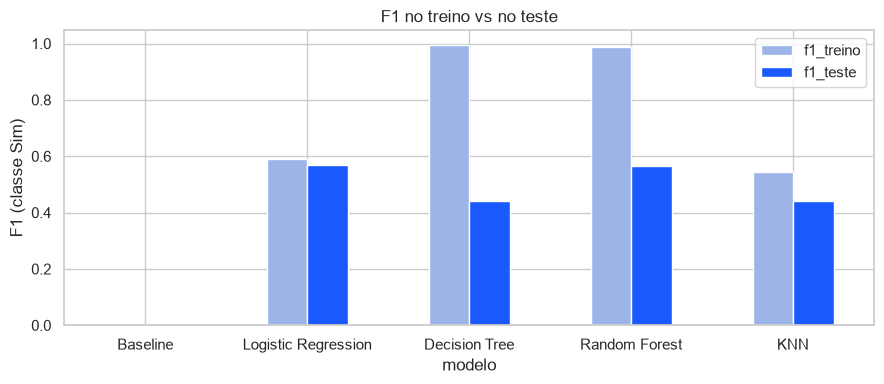

In [8]:
ax = resultados[["f1_treino", "f1_teste"]].plot(kind="bar", figsize=(9, 4), rot=0, color=["#9DB4E8", "#1A59FD"])
ax.set_ylabel("F1 (classe Sim)")
ax.set_title("F1 no treino vs no teste")
plt.tight_layout()
guardar_figura("04-2.3-f1_treino_vs_teste")
plt.show()

##### Análise e Interpretação

> *Que modelos mostram diferenças grandes entre treino e teste?*

**Resposta:**

- No gráfico, a Decision Tree e a Random Forest têm a barra do treino perto de 1 e a do teste muito mais baixa: é o overfitting da tabela anterior.
- O KNN tem uma diferença menor, mas também fica com um F1 baixo nos dois conjuntos.
- A Logistic Regression tem as duas barras quase à mesma altura: aprende menos detalhe, mas o que aprende generaliza.
- O baseline não aparece (F1 = 0 em ambos).

<hr>

#### 2.4 Validação cruzada (M5)

Uma única divisão treino/teste depende da amostra que calhou. O **K-Fold** divide em K partes, treina em K−1 e testa na restante, K vezes; em classificação usa-se `StratifiedKFold`. Comparamos pela **média** (desempenho) e pelo **desvio padrão** (estabilidade).

Aqui a validação cruzada é feita **só com o treino** — o teste fica reservado para a avaliação final.

**2.4 [Classificação] Validação cruzada (M5)**
- `cross_val_score` com a `StratifiedKFold`, **só no treino**, para cada modelo: média ± desvio.
- Boxplot dos scores por fold.

Baseline: 0.000 ± 0.000
Logistic Regression: 0.589 ± 0.008
Decision Tree: 0.447 ± 0.006
Random Forest: 0.586 ± 0.014
KNN: 0.452 ± 0.015
Figura guardada em: Data\analytics\04-2.4-cv_boxplot_modelos_base.png


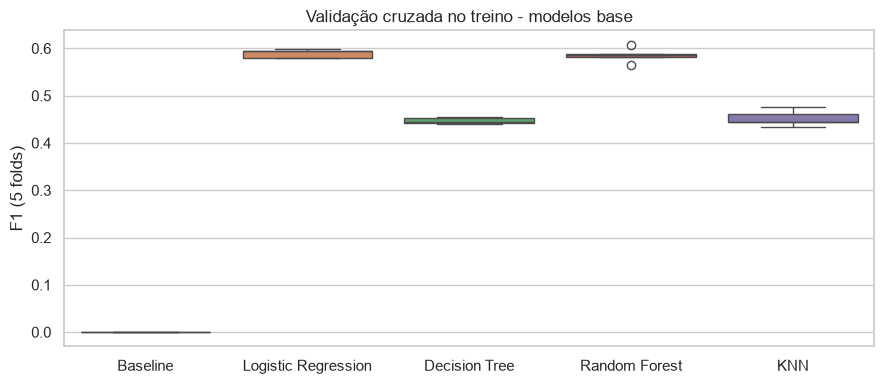

In [9]:
scores_cv = {}
for nome, modelo in modelos.items():
    scores_cv[nome] = cross_val_score(modelo, X_train, y_train, cv=cv, scoring=METRICA, n_jobs=-1)
    print(f"{nome}: {scores_cv[nome].mean():.3f} ± {scores_cv[nome].std():.3f}")

plt.figure(figsize=(9, 4))
sns.boxplot(data=pd.DataFrame(scores_cv))
plt.ylabel("F1 (5 folds)")
plt.title("Validação cruzada no treino - modelos base")
plt.tight_layout()
guardar_figura("04-2.4-cv_boxplot_modelos_base")
plt.show()

##### Análise e Interpretação

> *Que modelo é melhor em média? E o mais estável (menor desvio)? A conclusão muda face ao teste?*

**Resposta:**

- **Melhor em média:** Logistic Regression (F1 0,589 ± 0,008), logo seguida da Random Forest (0,586 ± 0,014). A Decision Tree (0,447) e o KNN (0,452) ficam bastante atrás.
- **Mais estável:** a Decision Tree tem o menor desvio (0,006), mas é estável num valor fraco; entre os bons modelos, a logística (0,008) é mais estável do que a Random Forest (0,014).
- **A conclusão muda face ao teste?** Não. A ordem é a mesma (logística ≈ Random Forest > KNN ≈ árvore) e os valores da CV estão muito próximos dos do teste (ex.: logística 0,589 na CV vs 0,570 no teste), o que dá confiança de que a CV é uma boa estimativa.
- Nos modelos base, nenhum chega ainda aos F1 de 0,60+, por isso vale a pena afinar os hiperparâmetros, sobretudo das árvores, que estão em overfitting.

<hr>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">TUNING DE HIPERPARÂMETROS</div>

### 5. Tuning de hiperparâmetros (M5)
<hr>

Os **parâmetros** são aprendidos pelo modelo no treino (ex.: coeficientes). Os **hiperparâmetros** escolhemo-los nós, antes do treino, e controlam a complexidade do modelo:

| Modelo | Hiperparâmetro | Efeito |
|---|---|---|
| Decision Tree | `max_depth` | profundidade máxima; valores altos → overfitting |
| | `min_samples_split` / `min_samples_leaf` | mínimo de amostras para dividir um nó / numa folha; valores altos → modelo mais simples |
| Random Forest | `n_estimators` | nº de árvores; mais árvores = mais estabilidade (e mais custo) |
| | `max_depth`, `max_features` | complexidade de cada árvore; variáveis consideradas em cada divisão |
| KNN | `n_neighbors` | K pequeno → overfitting; K grande → underfitting |
| | `weights`, `metric` | uniforme ou ponderado pela distância; tipo de distância |
| Logistic Regression | `C` | inverso da regularização; C pequeno → modelo mais simples |
| K-Means | `n_clusters`, `n_init` | nº de grupos (escolhido na secção 4); nº de inicializações |

**Regras (M5):**
1. **GridSearchCV** testa todas as combinações de uma grelha, com validação cruzada **sobre o treino**; o teste fica reservado para a avaliação final.
2. Num `Pipeline`, o hiperparâmetro leva o prefixo do passo: `clf__max_depth` (classificação) ou `reg__max_depth` (regressão).
3. `best_estimator_` já vem treinado com os melhores parâmetros.
4. Comparar sempre o modelo afinado com o modelo base: o ganho compensa a complexidade?

#### 5.1 `GridSearchCV` — pesquisa exaustiva (M5)

**5.1 [Classificação] GridSearchCV (M5)**
- Para pelo menos 2 modelos, definir uma grelha de hiperparâmetros (prefixo `clf__`, ex.: `{"clf__n_estimators": [100, 200], "clf__max_depth": [4, 8, None]}`) e correr `GridSearchCV` com a validação cruzada, **só no treino**.
- Mostrar `best_params_` e `best_score_` e guardar os `best_estimator_`.

In [10]:
grelhas = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"clf__max_depth": [4, 6, 8, 10, 12], "clf__min_samples_leaf": [1, 10, 30, 50]},
    "Random Forest": {"clf__max_depth": [8, 12, 16, None], "clf__min_samples_leaf": [1, 5, 10]},
    "KNN": {"clf__n_neighbors": [5, 15, 31, 51], "clf__weights": ["uniform", "distance"]},
}

afinados, melhor_score, tempos = {}, {}, {}
for nome, grelha in grelhas.items():
    inicio = time.perf_counter()
    gs = GridSearchCV(modelos[nome], grelha, scoring=METRICA, cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)  # só treino
    tempos[nome] = time.perf_counter() - inicio
    afinados[nome + " (Grid)"] = gs.best_estimator_
    melhor_score[nome + " (Grid)"] = gs.best_score_
    print(f"{nome}: base {scores_cv[nome].mean():.3f} -> afinado {gs.best_score_:.3f} ({tempos[nome]:.0f}s) {gs.best_params_}")

Logistic Regression: base 0.589 -> afinado 0.590 (1s) {'clf__C': 10}
Decision Tree: base 0.447 -> afinado 0.623 (3s) {'clf__max_depth': 8, 'clf__min_samples_leaf': 50}
Random Forest: base 0.586 -> afinado 0.628 (63s) {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
KNN: base 0.452 -> afinado 0.461 (4s) {'clf__n_neighbors': 31, 'clf__weights': 'uniform'}


##### Análise e Interpretação

> *Que hiperparâmetros foram escolhidos? Quanto melhorou o score de validação cruzada face ao modelo base?*

**Resposta:**

- **Decision Tree:** foi a que mais melhorou, de 0,447 para **0,623** com `max_depth=8` e `min_samples_leaf=50`. Limitar a profundidade e obrigar a folhas maiores tira o overfitting.
- **Random Forest:** de 0,586 para **0,628** com `min_samples_leaf=5` (sem limite de profundidade). Folhas com pelo menos 5 candidatos chegam para a floresta deixar de decorar o treino.
- **Logistic Regression:** praticamente não muda (0,589 → 0,590 com `C=10`). Menos regularização quase não tem efeito, porque a logística já estava no seu limite (relações não lineares que não consegue captar).
- **KNN:** melhora pouco (0,452 → 0,461 com `n_neighbors=31`) e continua com recall baixo, porque não tem forma de compensar o desequilíbrio das classes.
- Todas as pesquisas foram feitas só com `X_train`/`y_train`, com a mesma `StratifiedKFold` dos modelos base.

<hr>

#### 5.2 `RandomizedSearchCV` — pesquisa aleatória (referido no M5)

Amostra `n_iter` combinações ao acaso — muito mais rápido em espaços grandes, normalmente com resultado próximo do GridSearch.

**5.2 [Classificação] RandomizedSearchCV**
- Num espaço de procura maior (ex.: Random Forest com `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`), `RandomizedSearchCV` com `n_iter` combinações.

In [11]:
espaco = {
    "clf__n_estimators": randint(100, 400),
    "clf__max_depth": [8, 12, 16, 20, None],
    "clf__min_samples_leaf": randint(1, 30),
    "clf__max_features": ["sqrt", 0.3, 0.5],
}

inicio = time.perf_counter()
rs = RandomizedSearchCV(modelos["Random Forest"], espaco, n_iter=20, scoring=METRICA, cv=cv,
                        random_state=RANDOM_STATE, n_jobs=-1)
rs.fit(X_train, y_train)
tempo_rs = time.perf_counter() - inicio

afinados["Random Forest (Random)"] = rs.best_estimator_
melhor_score["Random Forest (Random)"] = rs.best_score_
print(f"Random: {rs.best_score_:.3f} em {tempo_rs:.0f}s (20 combinações) {rs.best_params_}")
print(f"Grid:   {melhor_score['Random Forest (Grid)']:.3f} em {tempos['Random Forest']:.0f}s (12 combinações)")

Random: 0.638 em 125s (20 combinações) {'clf__max_depth': 20, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 230}
Grid:   0.628 em 63s (12 combinações)


##### Análise e Interpretação

> *O resultado é próximo do GridSearch? Compensa o tempo poupado?*

**Resposta:**

- O `RandomizedSearchCV` encontrou um resultado **um pouco melhor** do que o GridSearch: F1 de **0,638** (vs 0,628), com `n_estimators=230`, `max_depth=20`, `min_samples_leaf=20` e `max_features=0.5`.
- Foi melhor porque explorou hiperparâmetros que não estavam na grelha, sobretudo `max_features` (cada árvore só vê metade das colunas em cada divisão) e folhas maiores (20).
- **Tempo:** aqui não houve poupança de tempo, demorou mais (135 s vs 77 s) porque testou 20 combinações contra 12 da grelha e com mais árvores. A vantagem é outra: com o mesmo esforço, cobriu um espaço de 4 hiperparâmetros que, em grelha, daria centenas de combinações. Compensa.

<hr>

#### 5.3 Curva de validação (complemento)

Ajuda a **ver** o efeito de um hiperparâmetro: para cada valor, compara o score no treino e na validação cruzada — treino alto e validação baixa → overfitting; ambos baixos → underfitting.

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>A curva de validação não foi dada em aula; usa apenas <code>cross_validate</code> (variante do <code>cross_val_score</code> que também devolve o score no treino). É opcional.</div>

**5.3 (Complemento) Curva de validação**
- Para um hiperparâmetro (ex.: `max_depth` da árvore), calcular o score no treino e na validação cruzada para vários valores (`cross_validate(..., return_train_score=True)`) e desenhar as duas curvas.

Figura guardada em: Data\analytics\04-5.3-curva_validacao_max_depth.png


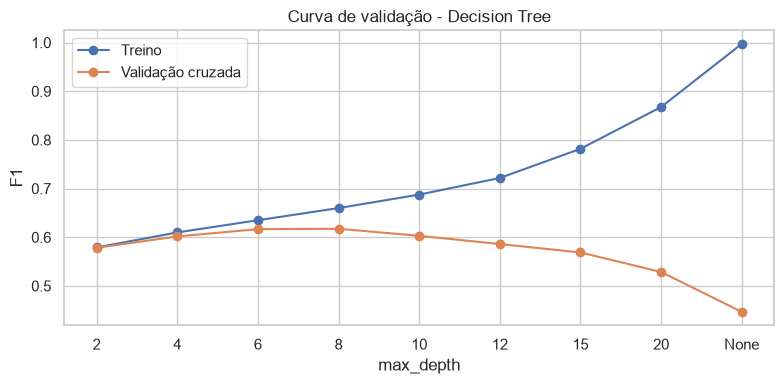

,max_depth,f1_treino,f1_cv
0,2,0.579,0.578
1,4,0.610,0.602
2,6,0.635,0.617
3,8,0.660,0.617
4,10,0.688,0.603
5,12,0.722,0.586
6,15,0.782,0.569
7,20,0.868,0.529
8,None,0.997,0.447


In [12]:
profundidades = [2, 4, 6, 8, 10, 12, 15, 20, None]
f1_treino, f1_cv = [], []
for d in profundidades:
    arvore = criar_pipeline(DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE), scaling=False)
    r = cross_validate(arvore, X_train, y_train, cv=cv, scoring=METRICA, return_train_score=True, n_jobs=-1)
    f1_treino.append(r["train_score"].mean())
    f1_cv.append(r["test_score"].mean())

x = [str(d) for d in profundidades]
plt.figure(figsize=(8, 4))
plt.plot(x, f1_treino, marker="o", label="Treino")
plt.plot(x, f1_cv, marker="o", label="Validação cruzada")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Curva de validação - Decision Tree")
plt.legend()
plt.tight_layout()
guardar_figura("04-5.3-curva_validacao_max_depth")
plt.show()

pd.DataFrame({"max_depth": x, "f1_treino": f1_treino, "f1_cv": f1_cv}).round(3)

##### Análise e Interpretação

> *A partir de que valor o modelo começa a sobreajustar?*

**Resposta:**

- Até `max_depth` = 6–8 as duas curvas sobem juntas e o F1 na validação cruzada chega ao máximo (**0,617**).
- **A partir de 8 o modelo começa a sobreajustar:** o F1 no treino continua a subir (0,660 → 0,722 → 0,868) e o da CV desce (0,617 → 0,586 → 0,529). Sem limite (`None`), o treino chega a 0,997 e a CV cai para 0,447.
- Com profundidade 2 as curvas estão juntas mas baixas (0,58): é underfitting.
- Confirma o GridSearch (melhor `max_depth=8`).

<hr>

<div style="background:#FF5B34; color:#fff; font-weight:700; padding:8px 14px; border-radius:3px; font-family:Segoe UI, Arial, sans-serif; font-size:16px;">COMPARAÇÃO FINAL E ESCOLHA DO MODELO</div>

### 6. Comparação final e seleção do modelo
<hr>

Todos os candidatos (modelos base + afinados) comparados com os **mesmos critérios** (M5):
- **média da validação cruzada** (treino) → base da escolha — escolhemos o modelo que generaliza melhor, não o de maior métrica pontual;
- desvio padrão da CV (estabilidade); o desempenho no **teste** é apenas confirmação, não critério de escolha;
- diagnóstico treino/teste (overfitting), interpretabilidade, custo e risco do erro.

**6.1 [Classificação] Comparação final**
- Para todos os candidatos (modelos base + afinados): média e desvio da CV (treino) e métricas no teste; diagnóstico de overfitting.

In [13]:
candidatos = {**modelos, **afinados}

linhas = []
for nome, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["f1", "recall", "precision", "roc_auc"],
                       return_train_score=True, n_jobs=-1)
    modelo.fit(X_train, y_train)
    te = avaliar(modelo, X_test, y_test)
    linhas.append([nome, r["test_f1"].mean(), r["test_f1"].std(), r["test_recall"].mean(), r["test_precision"].mean(),
                   r["test_roc_auc"].mean(), r["train_f1"].mean(), te["f1"], te["recall"], te["precision"], te["roc_auc"]])

comparacao = pd.DataFrame(linhas, columns=["modelo", "f1_cv_media", "f1_cv_desvio", "recall_cv", "precision_cv", "roc_auc_cv",
                                           "f1_treino_cv", "f1_teste", "recall_teste", "precision_teste", "roc_auc_teste"])
comparacao = comparacao.set_index("modelo").sort_values("f1_cv_media", ascending=False)
comparacao["dif_f1 (treino - CV)"] = comparacao["f1_treino_cv"] - comparacao["f1_cv_media"]
comparacao["diagnostico"] = np.where(comparacao["dif_f1 (treino - CV)"] > 0.10, "overfitting", "ok")
comparacao.round(3)

,f1_cv_media,f1_cv_desvio,recall_cv,precision_cv,roc_auc_cv,f1_treino_cv,f1_teste,recall_teste,precision_teste,roc_auc_teste,dif_f1 (treino - CV),diagnostico
modelo,,,,,,,,,,,,
Random Forest (Random),0.638,0.007,0.745,0.558,0.803,0.654,0.613,0.715,0.536,0.792,0.016,ok
Random Forest (Grid),0.628,0.008,0.750,0.540,0.802,0.673,0.616,0.733,0.532,0.790,0.045,ok
Decision Tree (Grid),0.623,0.011,0.740,0.538,0.795,0.636,0.596,0.723,0.507,0.784,0.013,ok
Logistic Regression (Grid),0.590,0.008,0.762,0.481,0.786,0.591,0.571,0.732,0.468,0.769,0.001,ok
Logistic Regression,0.589,0.008,0.761,0.481,0.786,0.591,0.570,0.732,0.467,0.769,0.001,ok
Random Forest,0.586,0.014,0.629,0.548,0.785,0.991,0.566,0.612,0.526,0.776,0.405,overfitting
KNN (Grid),0.461,0.014,0.392,0.560,0.781,0.511,0.437,0.371,0.532,0.771,0.049,ok
KNN,0.452,0.015,0.393,0.532,0.769,0.544,0.443,0.384,0.522,0.756,0.092,ok
Decision Tree,0.447,0.006,0.445,0.449,0.632,0.997,0.440,0.449,0.432,0.627,0.551,overfitting


##### Análise e Interpretação

> *Qual o modelo que generaliza melhor? A ordenação pela CV coincide com a do teste?*

**Resposta:**

- **O modelo que generaliza melhor é a Random Forest afinada com o RandomizedSearch:** F1 na CV de **0,638 ± 0,007**, recall 0,745 e ROC-AUC 0,803. É também o mais estável dos modelos bons (menor desvio) e a diferença treino−CV é pequena (0,016), sem overfitting.
- A seguir vêm a Random Forest (Grid) com 0,628 e a Decision Tree (Grid) com 0,623. A logística fica nos 0,590 e o KNN nos 0,46.
- **A ordem da CV coincide quase toda com a do teste.** A única troca está no topo: no teste a Random Forest (Grid) tem um F1 ligeiramente maior (0,616 vs 0,613). A diferença é de 0,003, muito menor do que o desvio entre folds, por isso não muda a escolha (escolher pelo teste seria usar o teste como validação).
- Os modelos sem tuning (Decision Tree e Random Forest base) aparecem com diagnóstico de overfitting (diferença treino−CV > 0,10). Todos os afinados ficaram "ok".

<hr>

**6.2 Escolher o modelo final**
- Guardar o nome do modelo escolhido e o respetivo pipeline em `modelo_final` (não pode ser o baseline).

In [14]:
# a escolha é pela média da CV no treino (não pelo teste), e o baseline não conta
nome_final = comparacao.drop(index="Baseline")["f1_cv_media"].idxmax()
modelo_final = candidatos[nome_final]

print("Modelo escolhido:", nome_final)
print(comparacao.loc[nome_final, ["f1_cv_media", "f1_cv_desvio", "recall_cv", "f1_teste"]].round(3))
print(modelo_final.named_steps["clf"])

Modelo escolhido: Random Forest (Random)
f1_cv_media     0.638
f1_cv_desvio    0.007
recall_cv       0.745
f1_teste        0.613
Name: Random Forest (Random), dtype: float64
RandomForestClassifier(class_weight='balanced', max_depth=20, max_features=0.5,
                       min_samples_leaf=20, n_estimators=230, n_jobs=-1,
                       random_state=42)


<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Se nenhum modelo supera <b>claramente</b> o baseline, isso também é um resultado: pode significar que as variáveis disponíveis têm pouca capacidade explicativa. Nesse caso, discutam-no na Fase 5 e voltem às Fases 2/3 (novas variáveis, outros dados) em vez de forçar um modelo.</div>

#### Justificação da escolha do modelo final

| Critério | Avaliação |
|---|---|
| Desempenho (média da CV e teste) | Melhor F1 na CV (0,638) de todos os candidatos; no teste 0,613 (2.º, a 0,003 do primeiro) |
| Estabilidade (desvio padrão na CV) | 0,007, o menor entre os modelos com F1 > 0,60 |
| Generalização (diagnóstico treino/teste) | Treino 0,654 vs CV 0,638 vs teste 0,613: sem overfitting (a Random Forest base tinha 0,99 no treino) |
| Ganho face ao baseline e ao modelo mais simples | Baseline: F1 = 0 → 0,613. Logística: +0,05 de F1 na CV com recall semelhante |
| Interpretabilidade | Média: não dá regras simples como uma árvore, mas temos `feature_importances_` e permutation importance (Fase 5) |
| Custo / tempo de treino e previsão | Treino de alguns segundos (230 árvores); a previsão de milhares de candidatos é instantânea |
| Risco do erro (que erro é mais grave?) | O FN é o mais grave (candidato recetivo perdido); recall 0,715 com o limiar por defeito, ajustável na Fase 5 |

**Modelo escolhido e justificação:**

- **Random Forest afinada com `RandomizedSearchCV`**, escolhida por ter a melhor média de F1 na validação cruzada e o menor desvio entre os modelos bons, sem overfitting. O teste só serviu para confirmar: não se escolheu a Random Forest (Grid) por ter mais 0,003 de F1 no teste, porque isso seria usar o teste para decidir.
- A Decision Tree (Grid) era uma alternativa mais interpretável (F1 CV 0,623), mas perde em F1 e estabilidade; como o objetivo principal é encontrar os candidatos recetivos, preferimos o desempenho, e a interpretação é feita com a importância das variáveis na Fase 5.

### 7. Avaliação detalhada do modelo final no teste (M5)
<hr>

- **Classificação:** matriz de confusão, `classification_report` (precision, recall e F1 por classe), curva ROC e AUC
- **Regressão:** real vs previsto, resíduos vs previsto, distribuição dos resíduos

**7.1 [Classificação] Matriz de confusão e classification report (M5)**
- `confusion_matrix` + `ConfusionMatrixDisplay` e `classification_report` do modelo final no teste.

Figura guardada em: Data\analytics\04-7.1-matriz_confusao_modelo_final.png


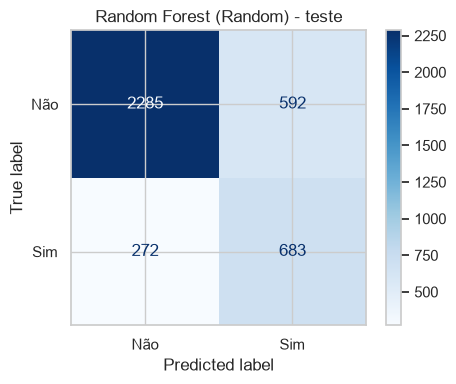

              precision    recall  f1-score   support

         Não      0.894     0.794     0.841      2877
         Sim      0.536     0.715     0.613       955

    accuracy                          0.775      3832
   macro avg      0.715     0.755     0.727      3832
weighted avg      0.804     0.775     0.784      3832



In [15]:
y_pred = modelo_final.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Não", "Sim"], cmap="Blues", ax=ax)
ax.set_title(f"{nome_final} - teste")
plt.tight_layout()
guardar_figura("04-7.1-matriz_confusao_modelo_final")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Não", "Sim"], digits=3))

##### Análise e Interpretação

> *Onde erra o modelo? Que tipo de erro (FP ou FN) é mais frequente e qual é mais grave para o negócio?*

**Resposta:**

- O modelo final acerta 683 dos 955 candidatos que procuram mudar (**recall 0,715**) e 2 285 dos 2 877 que não procuram (0,794).
- **Erros:** 272 falsos negativos (procuram mudar mas o modelo diz que não) e 592 falsos positivos (o modelo diz que sim mas não procuram).
- Os **falsos positivos são mais frequentes**, mas os **falsos negativos são mais graves** para o negócio (Fase 1): um FN é um candidato recetivo que não é contactado (oportunidade perdida), enquanto um FP custa só um contacto a mais. É por isso que preferimos este equilíbrio, com mais FP do que FN.
- A precision da classe "Sim" é 0,536: em cada 2 candidatos contactados, cerca de 1 está mesmo à procura, o dobro dos ~25% que teríamos a contactar ao acaso.

<hr>

**7.2 [Classificação binária] Curva ROC e AUC (M5)**
- `predict_proba`, `roc_curve` e `roc_auc_score`; desenhar a curva com a diagonal de referência.

Figura guardada em: Data\analytics\04-7.2-curva_roc_modelo_final.png


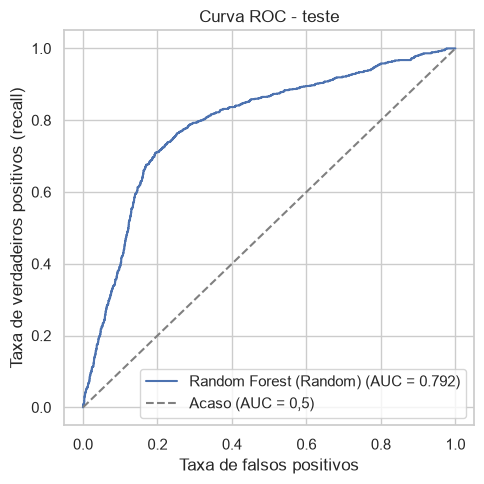

In [16]:
y_prob = modelo_final.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"{nome_final} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Acaso (AUC = 0,5)")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos (recall)")
plt.title("Curva ROC - teste")
plt.legend()
plt.tight_layout()
guardar_figura("04-7.2-curva_roc_modelo_final")
plt.show()

##### Análise e Interpretação

> *Qual o AUC? O que significa este valor na prática?*

**Resposta:**

- **AUC = 0,792** no teste (0,803 na CV).
- Na prática: se escolhermos ao acaso um candidato que procura mudar e um que não procura, o modelo dá uma probabilidade mais alta ao primeiro em cerca de 79% dos casos. Um modelo ao acaso ficava nos 50%.
- A curva fica bem acima da diagonal, mas longe do canto superior esquerdo: o modelo ordena bem os candidatos, mas há sobreposição entre os dois grupos (já se via na Fase 2, sem uma variável que os separe totalmente).

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Matriz de confusão</b>: linhas = real, colunas = previsto; VP, VN, FP, FN.</li><li><b>Precision</b>: dos previstos positivos, quantos certos · <b>Recall</b>: dos positivos reais, quantos apanhados · <b>F1</b>: equilíbrio.</li><li><b>ROC</b>: quanto mais perto do canto superior esquerdo, melhor. AUC = 1 perfeito; 0,5 = acaso.</li></ul></div>

**7.3 (Complemento) Curva Precision-Recall**
- `PrecisionRecallDisplay.from_estimator`.

Figura guardada em: Data\analytics\04-7.3-curva_precision_recall_modelo_final.png


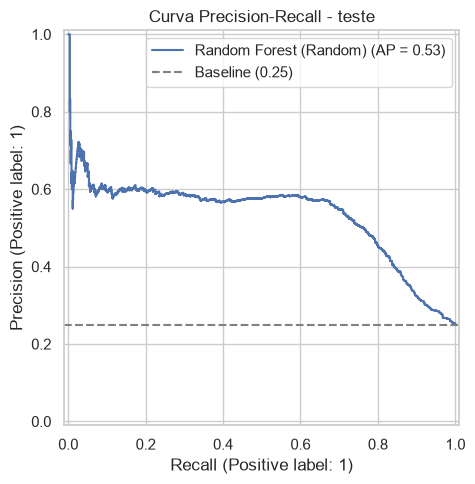

In [17]:
fig, ax = plt.subplots(figsize=(5, 5))
PrecisionRecallDisplay.from_estimator(modelo_final, X_test, y_test, name=nome_final, ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="grey", label=f"Baseline ({y_test.mean():.2f})")
ax.set_title("Curva Precision-Recall - teste")
ax.legend()
plt.tight_layout()
guardar_figura("04-7.3-curva_precision_recall_modelo_final")
plt.show()

##### Análise e Interpretação

> *O modelo mantém boa precision quando o recall aumenta?*

**Resposta:**

- Mais ou menos. A precision nunca é muito alta: mesmo nos 200 candidatos com probabilidade mais alta, só ~59% procuram mudar. Depois desce devagar à medida que o recall aumenta e, por volta de recall 0,7 (a nossa meta), fica perto de 0,54. Só cai a pique quando tentamos apanhar quase todos os "Sim".
- A precisão média (AP) é 0,53, mais do dobro da linha de referência (0,25, a proporção de "Sim"), por isso o modelo acrescenta valor mesmo nesta métrica, que é mais exigente com classes desequilibradas.
- Para o negócio, o ponto de equilíbrio (recall ~0,70, precision ~0,55) é aceitável; o limiar exato é escolhido na Fase 5 com a CV.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li>Pontos próximos da diagonal → boas previsões; afastados → erros grandes em certas faixas.</li><li>Padrão curvo nos resíduos → não linearidade não captada.</li><li>Dispersão a aumentar com o valor previsto → o erro cresce com o valor (heterocedasticidade).</li></ul></div>

#### Análise de Resultados

- O modelo apresenta overfitting ou underfitting? Há grande diferença entre treino e teste?
- Os resultados no teste são coerentes com a validação cruzada?
- Os resultados fazem sentido no contexto do problema?

**Resposta:**

- **Overfitting/underfitting:** o modelo final não tem overfitting relevante: F1 de 0,654 no treino (folds de treino), 0,638 na CV e 0,613 no teste. A diferença treino−teste (~0,04) está bem abaixo do limite de 0,10. Também não é underfitting, porque supera claramente modelos mais simples (logística 0,590) e o baseline.
- **Coerência com a CV:** sim. O F1 no teste (0,613) fica ~0,025 abaixo da média da CV, uma queda pequena e esperada (há sempre algum otimismo quando se escolhe o melhor de 10 candidatos pela CV). O recall (0,745 na CV vs 0,715 no teste) e o AUC (0,803 vs 0,792) seguem o mesmo padrão.
- **Faz sentido no contexto?** Sim. O modelo cumpre as metas da Fase 1 (recall ≥ 0,70 e F1 ≥ 0,55) com o limiar por defeito, e o tipo de erro mais frequente (FP) é o menos grave para o negócio. A Random Forest capta bem as relações não lineares e as categorias "Em falta" que a Fase 2 mostrou serem importantes.

<hr>

### 8. Guardar o modelo e os resultados (M5)
<hr>

Guarda-se o **pipeline completo** (preparação + modelo) com `joblib` — em produção basta carregá-lo e prever.

- `Data/models/<PROJETO>_modelo_final.joblib` — usado nas Fases 5 e 6
- `Data/models/<PROJETO>_modelo_final.json` — metadados (nome, hiperparâmetros, data)
- `Data/output/<PROJETO>_comparacao_modelos.csv` — tabela de comparação

**8. Guardar o modelo e os resultados (M5)** (necessário para os notebooks 05 e 06)
- `joblib.dump(modelo_final, "Data/models/<PROJETO>_modelo_final.joblib")`.
- Gravar `Data/models/<PROJETO>_modelo_final.json` com: `modelo` (nome), `problema`, `target`, `features`, `hiperparametros` e `data_treino`.
- Gravar a tabela de comparação em `Data/output/<PROJETO>_comparacao_modelos.csv`.
- Recarregar o modelo com `joblib.load` para confirmar.

In [19]:
caminho_modelo = Path("Data/models") / f"{PROJETO}_modelo_final.joblib"
joblib.dump(modelo_final, caminho_modelo)

info = {
    "modelo": nome_final,
    "problema": PROBLEM_TYPE,
    "target": TARGET,
    "features": FEATURES,
    "metrica_principal": METRICA,
    "hiperparametros": modelo_final.named_steps["clf"].get_params(),
    "f1_cv_media": comparacao.loc[nome_final, "f1_cv_media"],
    "f1_teste": comparacao.loc[nome_final, "f1_teste"],
}
with open(Path("Data/models") / f"{PROJETO}_modelo_final.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2, default=str)

comparacao.to_csv(Path("Data/output") / f"{PROJETO}_comparacao_modelos.csv")

# confirmar que o modelo gravado dá as mesmas previsões
modelo_lido = joblib.load(caminho_modelo)
print("Previsões iguais depois de recarregar:", (modelo_lido.predict(X_test) == y_pred).all())

Previsões iguais depois de recarregar: True


### 9. Síntese da Fase de Modelação
<hr>

**Descrever:**
- Modelos testados (e baseline)
- Hiperparâmetros ajustados e método usado
- Melhor modelo e métricas obtidas (CV e teste)
- Limitações identificadas
- Próximos passos (se aplicável)

***Objetivo:*** documentar a modelação antes da avaliação de negócio.

**Resposta:**

- **Modelos testados:** baseline (classe maioritária), Logistic Regression, Decision Tree, Random Forest e KNN, todos dentro do mesmo Pipeline da Fase 3 (imputação + encoding + `RobustScaler` nos modelos sensíveis à escala). Usou-se `class_weight="balanced"` por causa do desequilíbrio (25% de "Sim").
- **Tuning:** `GridSearchCV` nos 4 modelos (`C`; `max_depth`/`min_samples_leaf`; `n_neighbors`/`weights`) e `RandomizedSearchCV` na Random Forest (20 combinações de `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`), sempre com `StratifiedKFold` (5 folds) só no treino e F1 como métrica. Curva de validação para o `max_depth` da árvore.
- **Melhor modelo:** Random Forest (Random) com `n_estimators=230`, `max_depth=20`, `min_samples_leaf=20`, `max_features=0.5` e `class_weight="balanced"`. CV: F1 0,638 ± 0,007, recall 0,745, ROC-AUC 0,803. Teste: F1 0,613, recall 0,715, precision 0,536, ROC-AUC 0,792, accuracy 0,775.
- **Limitações:** a precision fica pelos 0,54 (muitos contactos sem interesse); a Random Forest é menos interpretável do que uma árvore ou a logística; o desempenho depende muito das variáveis "Em falta" e do índice da cidade; o tuning foi limitado (grelhas pequenas, 20 iterações).
- **Próximos passos:** na Fase 5, ajustar o limiar de decisão com a CV, analisar os erros por segmento (incluindo género, Q4) e a importância das variáveis. Fica como hipótese testar modelos de boosting (ex.: Gradient Boosting).

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Modelos adequados ao tipo de problema, com estratégia justificada</li><li>Implementação correta (Pipeline, <code>random_state</code>, sem leakage)</li><li>Comparação real entre vários modelos e com um baseline</li><li>Tuning de hiperparâmetros explorado de forma sistemática (GridSearchCV / RandomizedSearchCV)</li><li>Validação cruzada para avaliar estabilidade</li><li>Modelo e hiperparâmetros escolhidos pela validação cruzada, não pelo teste</li><li>Código organizado e reprodutível; modelo e resultados guardados</li><li>Justificação técnica da escolha final</li></ul></div>

[← Fase 3: Preparação dos Dados](03_data_preparation.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 5: Avaliação →](05_evaluation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>